<a href="https://colab.research.google.com/github/rajasri-26/EEG-Eye-State-Classification/blob/main/EEG_Eye_State_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EEG Eye State Classification Using Machine Learning Algorithms(SVM, KNN,Random Forest)

**Guide:** Ms.Sameera D

**Batch:** 4

**Authors:**



*   M.Akshaya[24911A66F7]
*   Premanvitha[25915A6618]

*   N.Rajasri[24911A66G7]


## PROBLEM STATEMENT

The objective of this project is to develop a machine learning model that predicts whether a person's eyes are open or closed based on EEG (Electroencephalogram) signals.

The dataset contains EEG measurements collected from a person. These measurements are used to identify the eye state.

The project aims to:

- Analyze the EEG Eye State dataset.
- Perform data preprocessing.
- Develop machine learning models using SVM, KNN, and Random Forest.
- Compare the performance of different algorithms.
- Visualize EEG data and model performance.
- Identify the best-performing model based on evaluation metrics.

## STEPS

1. Importing the required libraries.
2. Reading the EEG Eye State dataset.
3. Preprocessing the dataset.
4. Splitting the dataset into training and testing sets.
5. Building the models (SVM, KNN, and Random Forest).
6. Evaluating model performance and visualizing the results.

# 1.Importing the Library Files

In [ ]:
!pip install ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 2.Reading the EEG Eye State Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Fetch EEG Eye State dataset
eeg_data = fetch_ucirepo(id=264)

# Read features and target
X = eeg_data.data.features
y = eeg_data.data.targets.iloc[:, 0]

# Display dataset information
print("Dataset Shape:", X.shape)

print("\nFirst five records:")
print(X.head())

print("\nDataset Information:")
print(X.info())

print("\nMissing Values:")
print(X.isnull().sum())

print("\nStatistical Summary:")
print(X.describe())

Dataset Shape: (14980, 14)

First five records:
       AF3       F7       F3      FC5       T7       P7       O1       O2  \
0  4329.23  4009.23  4289.23  4148.21  4350.26  4586.15  4096.92  4641.03   
1  4324.62  4004.62  4293.85  4148.72  4342.05  4586.67  4097.44  4638.97   
2  4327.69  4006.67  4295.38  4156.41  4336.92  4583.59  4096.92  4630.26   
3  4328.72  4011.79  4296.41  4155.90  4343.59  4582.56  4097.44  4630.77   
4  4326.15  4011.79  4292.31  4151.28  4347.69  4586.67  4095.90  4627.69   

        P8       T8      FC6       F4       F8      AF4  
0  4222.05  4238.46  4211.28  4280.51  4635.90  4393.85  
1  4210.77  4226.67  4207.69  4279.49  4632.82  4384.10  
2  4207.69  4222.05  4206.67  4282.05  4628.72  4389.23  
3  4217.44  4235.38  4210.77  4287.69  4632.31  4396.41  
4  4210.77  4244.10  4212.82  4288.21  4632.82  4398.46  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14980 entries, 0 to 14979
Data columns (total 14 columns):
 #   Colum

# 3.Data Preprocessing


In [ ]:
print("Column Names:")
print(X.columns.tolist())

Column Names:
['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']


In [ ]:
print("Missing values in features:")
print(X.isnull().sum().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

# Remove missing values if present
data = X.copy()
data["Eye_State"] = y

data = data.dropna()

X = data.drop("Eye_State", axis=1)
y = data["Eye_State"]

print("\nDataset after preprocessing:")
print(data.shape)

Missing values in features:
0

Missing values in target:
0

Dataset after preprocessing:
(14980, 15)


In [ ]:
print("Eye State Counts:")
print(y.value_counts())

print("\nEye State Labels:")
print("0 = Eyes Open")
print("1 = Eyes Closed")

Eye State Counts:
Eye_State
0    8257
1    6723
Name: count, dtype: int64

Eye State Labels:
0 = Eyes Open
1 = Eyes Closed


In [ ]:
X = data.drop("Eye_State", axis=1)
y = data["Eye_State"]

print("Input Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature Shape: (14980, 14)
Target Shape: (14980,)


In [ ]:
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']


# 4.Split the Dataset into Training and Testing Sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 11984
Testing Records: 2996


# 5.Build the Machine Learning Models

In [ ]:
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

print("SVM Model Created Successfully")

SVM Model Created Successfully


In [ ]:
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

print("KNN Model Created Successfully")

KNN Model Created Successfully


In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest Model Created Successfully")

Random Forest Model Created Successfully


# 6.Train and Evaluate the Models

In [ ]:
models = {
    "SVM": svm,
    "KNN": knn,
    "Random Forest": random_forest
}

results = []
trained_models = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict eye state
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    trained_models[name] = model

    print("\n", name)
    print("-" * 40)

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Eyes Open", "Eyes Closed"],
        zero_division=0
    ))

# Create comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON:")
print(results_df.to_string(index=False))


 SVM
----------------------------------------
Accuracy: 0.6939
Precision: 0.8302
Recall: 0.4
F1-Score: 0.5399

Classification Report:
              precision    recall  f1-score   support

   Eyes Open       0.66      0.93      0.77      1651
 Eyes Closed       0.83      0.40      0.54      1345

    accuracy                           0.69      2996
   macro avg       0.74      0.67      0.66      2996
weighted avg       0.73      0.69      0.67      2996


 KNN
----------------------------------------
Accuracy: 0.9102
Precision: 0.9145
Recall: 0.8825
F1-Score: 0.8982

Classification Report:
              precision    recall  f1-score   support

   Eyes Open       0.91      0.93      0.92      1651
 Eyes Closed       0.91      0.88      0.90      1345

    accuracy                           0.91      2996
   macro avg       0.91      0.91      0.91      2996
weighted avg       0.91      0.91      0.91      2996


 Random Forest
----------------------------------------
Accuracy: 0.9309

# 7.Evaluate the Models Using Confusion Matrices

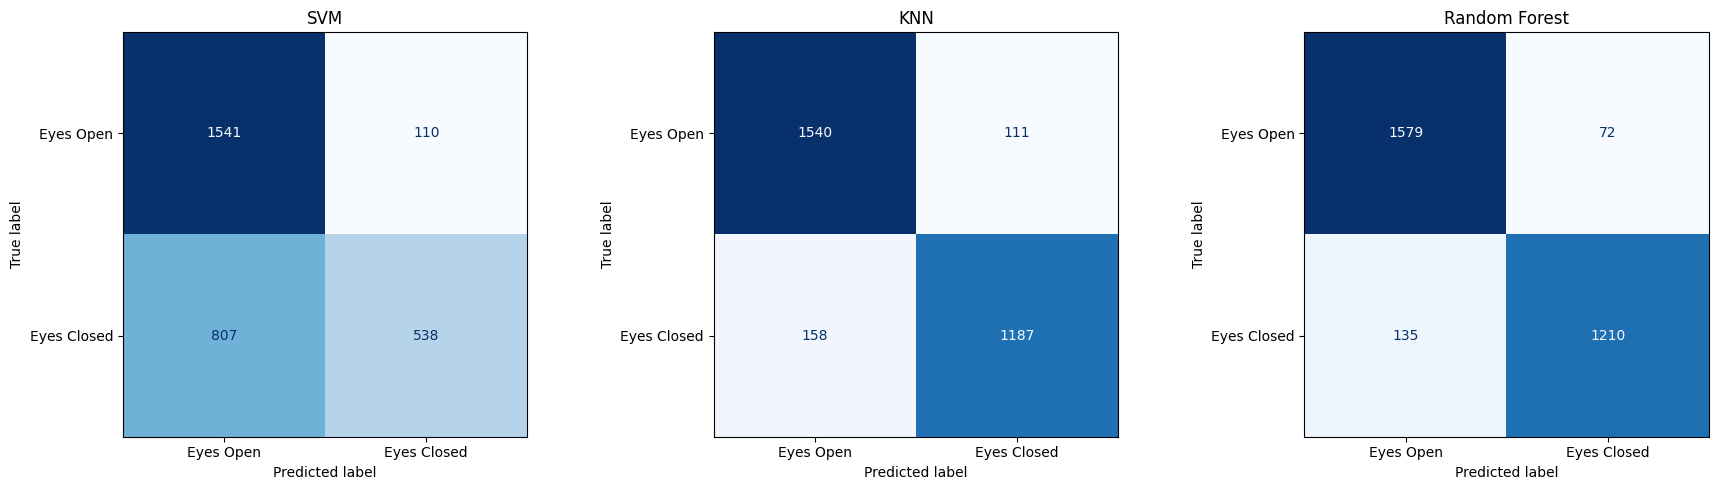

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Eyes Open", "Eyes Closed"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

# 8.Visualize the Dataset and Model Performance

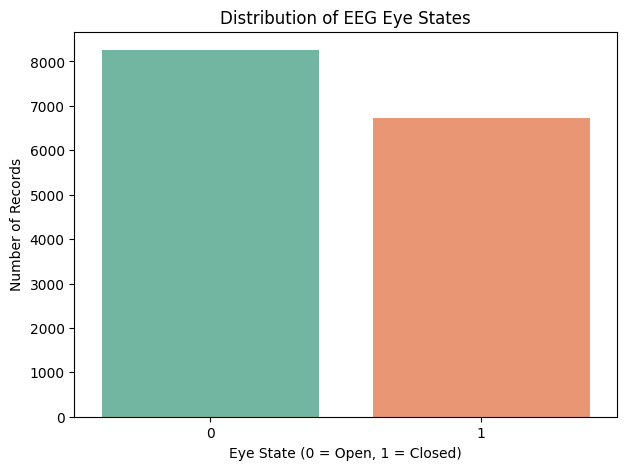

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Distribution of EEG Eye States")
plt.xlabel("Eye State (0 = Open, 1 = Closed)")
plt.ylabel("Number of Records")

plt.show()

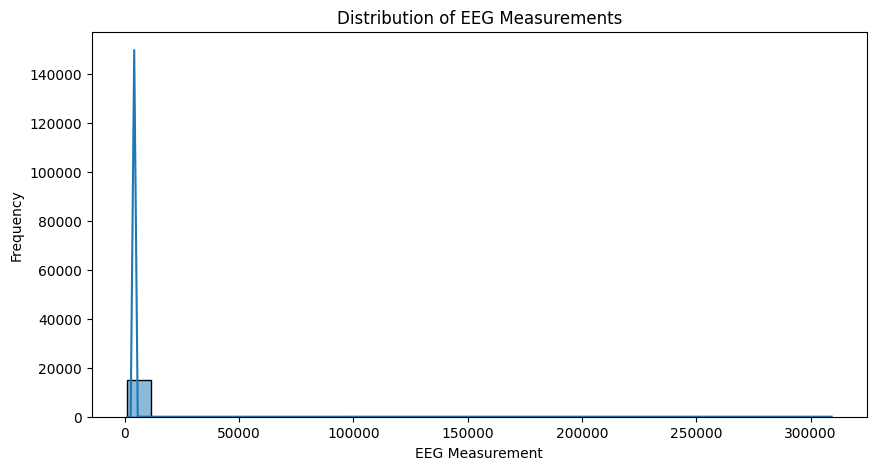

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=X,
    x=X.columns[0],
    bins=30,
    kde=True
)

plt.title("Distribution of EEG Measurements")
plt.xlabel("EEG Measurement")
plt.ylabel("Frequency")

plt.show()

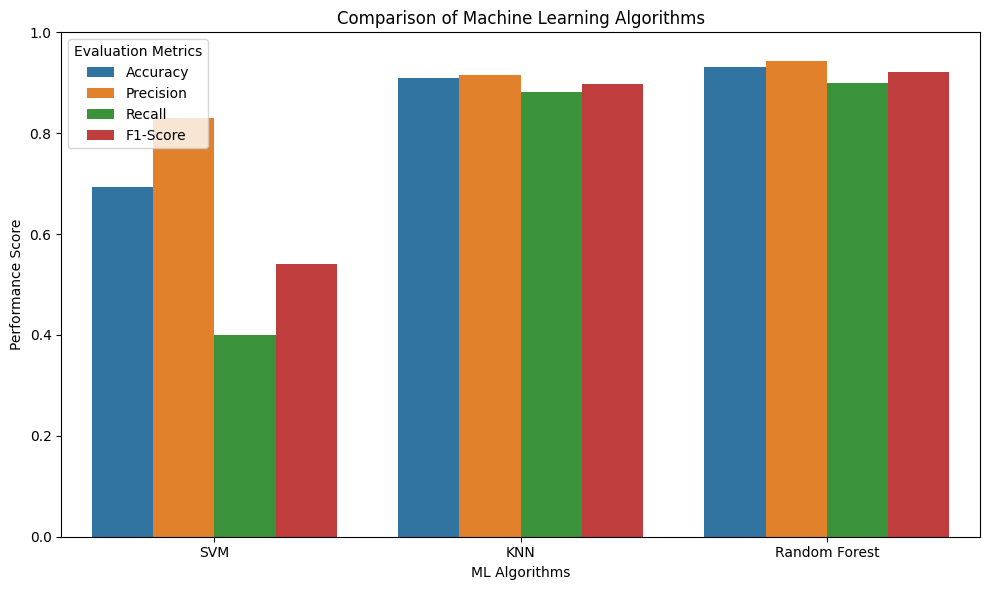

In [ ]:
plot_data = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Machine Learning Algorithms")
plt.xlabel("ML Algorithms")
plt.ylabel("Performance Score")
plt.ylim(0, 1)

plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

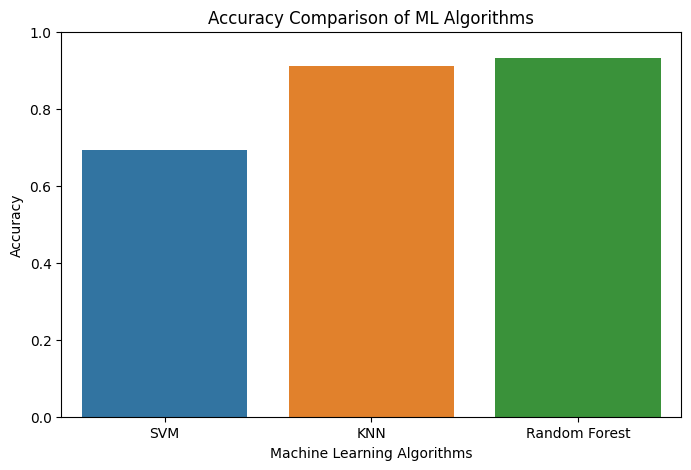

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    legend=False
)

plt.title("Accuracy Comparison of ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

# 9. Performance Evaluation Metrics
9.1 Accuracy
- Measures the percentage of correct predictions.
- Higher accuracy indicates better classification performance.
Formula:
\[
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
\]

9.2 Precision
- Measures how many predicted closed-eye cases are correct.
\[
Precision=\frac{TP}{TP+FP}
\]

9.3 Recall
- Measures how many actual closed-eye cases are correctly identified.
\[
Recall=\frac{TP}{TP+FN}
\]

9.4 F1-Score
- Combines precision and recall into one value.
\[
F1=2\times\frac{Precision\times Recall}{Precision+Recall}
\]

9.5 Confusion Matrix
- Displays correct and incorrect predictions.
- Helps identify classification errors.

# 10. Results and Analysis

In [ ]:
print("FINAL MODEL COMPARISON")

print(results_df.to_string(index=False))

print("\nBest Model Based on F1-Score:")

best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(),
    "Model"
]

print(best_model_name)

FINAL MODEL COMPARISON
        Model  Accuracy  Precision   Recall  F1-Score
          SVM  0.693925   0.830247 0.400000  0.539890
          KNN  0.910214   0.914484 0.882528  0.898222
Random Forest  0.930908   0.943838 0.899628  0.921203

Best Model Based on F1-Score:
Random Forest


Analysis of Results
- SVM: Separates eye states using decision boundaries.
- KNN: Predicts eye states using nearby EEG measurements.
- Random Forest: Uses multiple decision trees for classification.
- All three models are compared using evaluation metrics.
- The best model is selected based on the actual F1-score results.

# 11. Discussion
This project demonstrates how machine learning algorithms can classify eye states using EEG measurements.

The project uses three classification algorithms: SVM, KNN, and Random Forest.

The dataset is preprocessed and divided into training and testing sets. The models are trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Graphs are used to visualize eye-state distribution and compare model performance.
# 12. Conclusion
The EEG Eye State Classification project successfully demonstrates the application of machine learning in eye-state prediction.

The project uses 14 EEG measurements to classify whether a person's eyes are open or closed.

Three machine learning algorithms, SVM, KNN, and Random Forest, are implemented and compared.

Their performance is evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The best-performing model is identified based on the actual evaluation results.
# 13.Limitations
1. EEG signals may contain noise.
2. The dataset contains measurements from a single continuous recording.
3. Different individuals may have different EEG patterns.
4. Model performance depends on data quality.
5. The model may not perform equally well for every person.
6. Real-time EEG equipment is required for real-world predictions.
# 14. Future Enhancements
1. Use EEG data from multiple individuals.
2. Improve model performance using hyperparameter tuning.
3. Apply deep learning algorithms.
4. Develop a real-time eye-state detection system.
5. Create a user-friendly application for eye-state prediction.